# Chapitre 12 - Cours 6 : analytique prédictive, biais et boucles de rétroaction

Tout au long du livre, on a jugé les systèmes de données sur des critères techniques :
fiabilité, scalabilité, maintenabilité. La dernière section du chapitre, *Doing the Right Thing*, prend du recul : beaucoup de jeux de
données décrivent des **personnes**, et les décisions automatisées qu'on en tire ont des
conséquences voulues et non voulues sur leur vie. Les ingénieurs qui construisent ces
systèmes en portent une part de responsabilité. Les codes de déontologie existent (celui
de l'ACM par exemple), mais ils sont rarement discutés et encore moins appliqués ; et
l'éthique n'est pas une liste de cases à cocher, plutôt une réflexion continue, menée
avec les personnes concernées.

Ce notebook couvre la partie *Predictive Analytics* (sous-sections *Bias and discrimination*, *Responsibility and accountability*, *Feedback loops*).
Le livre argumente sans chiffres ; on va rendre chaque argument **mesurable** sur des
modèles jouets entièrement synthétiques (aucune donnée réelle) : quand on simule, les
mécanismes deviennent difficiles à nier.

**Plan.**

1. Prédire pour décider : l'asymétrie des erreurs et la « prison algorithmique ».
2. Biais et discrimination : un modèle qui n'a jamais vu l'attribut protégé.
3. Responsabilité, recours et explication.
4. Boucles de rétroaction.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import ethics as et
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Prédire pour décider : l'asymétrie des erreurs et la « prison algorithmique » (section *Predictive Analytics*)

Prédire la météo ou la progression d'une épidémie n'engage personne en particulier.
Prédire si **telle personne** va récidiver, rembourser un prêt ou coûter cher à son
assureur, c'est autre chose : la prédiction devient une décision qui touche
directement une vie.

**Pourquoi les organisations disent « non » au moindre doute.** Pour un prêteur, un bon
client refusé est une occasion manquée (gain perdu $g$), un mauvais client accepté est
une perte $\ell$ bien plus lourde. S'il estime à $p$ la probabilité de défaut, accepter
rapporte en moyenne $(1-p)\,g - p\,\ell$ : il accepte si et seulement si
$p < g / (g + \ell)$. Avec $\ell = 10\,g$, le seuil tombe à **9 %** : il suffit d'une
probabilité de défaut de 10 % pour être refusé, alors que 9 personnes sur 10 dans cette
situation auraient remboursé. Le calcul est rationnel pour l'organisation ; il fait
porter le coût de l'incertitude aux personnes.

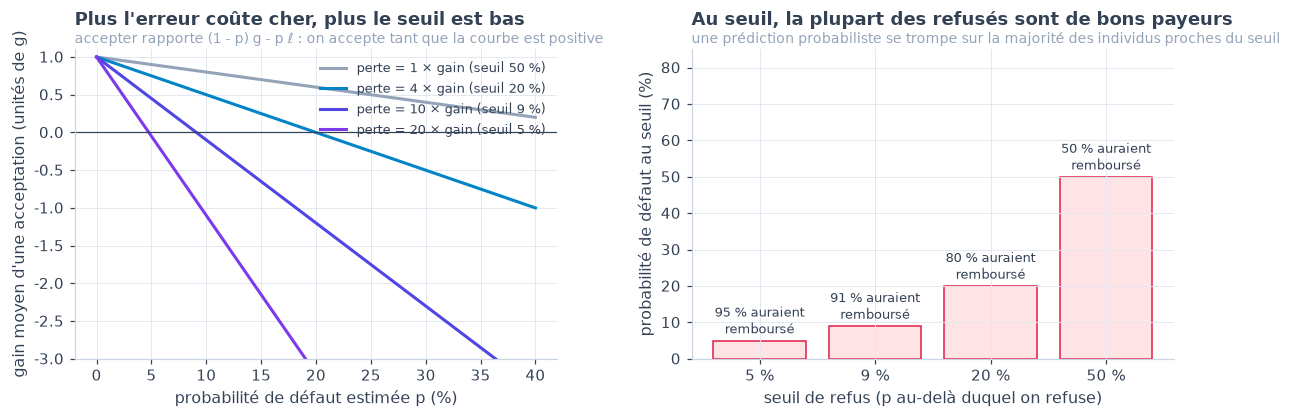

In [2]:
p = np.linspace(0, 0.4, 400)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
ax = axes[0]
for ratio, c in [(1, GRAY), (4, SKY), (10, INDIGO), (20, VIOLET)]:
    ax.plot(p * 100, (1 - p) - ratio * p, color=c, label=f"perte = {ratio} × gain (seuil {100 / (1 + ratio):.0f} %)")
ax.axhline(0, color=SLATE, lw=0.8)
ax.set_ylim(-3, 1.1)
ax.set_xlabel("probabilité de défaut estimée p (%)"); ax.set_ylabel("gain moyen d'une acceptation (unités de g)")
ax.set_title("Plus l'erreur coûte cher, plus le seuil est bas")
subtitle(ax, "accepter rapporte (1 - p) g - p ℓ : on accepte tant que la courbe est positive")
ax.legend(fontsize=8.5, loc="upper right")
ax = axes[1]
thr = np.array([0.05, 0.09, 0.2, 0.5])
ax.bar([f"{100 * t:.0f} %" for t in thr], [100 * t for t in thr], color=LIGHT[ROSE], edgecolor=ROSE,
       label="probabilité de défaut au seuil")
ax.set_ylabel("probabilité de défaut au seuil (%)"); ax.set_xlabel("seuil de refus (p au-delà duquel on refuse)")
for i, t in enumerate(thr):
    ax.text(i, 100 * t + 2, f"{100 - 100 * t:.0f} % auraient\nremboursé", ha="center", fontsize=8.5, color=SLATE)
ax.set_ylim(0, 85)
ax.set_title("Au seuil, la plupart des refusés sont de bons payeurs")
subtitle(ax, "une prédiction probabiliste se trompe sur la majorité des individus proches du seuil")
plt.tight_layout(); plt.show()

**De la décision isolée à l'exclusion systématique.** Un refus isolé est un désagrément.
Mais si les banques, les bailleurs, les assureurs, les employeurs et les compagnies
aériennes s'appuient sur **les mêmes données** (un même courtier, un même score), ils se
trompent sur **les mêmes personnes**. Être étiqueté « à risque », à tort ou à raison,
fait alors subir une avalanche de refus : on a parlé de **prison algorithmique**
(« algorithmic prison »). Là où la justice présume l'innocence et offre un appel, un
système automatisé peut exclure sans preuve et presque sans recours.

Simulons-le : 10 000 personnes, 10 organisations qui refusent chacune les 10 % de
dossiers jugés les plus risqués. Le score de chaque organisation est le risque réel plus
une erreur ; on fait varier la part $\rho$ de cette erreur qui est **commune** à toutes
(fonction `et.exclusion_counts`).

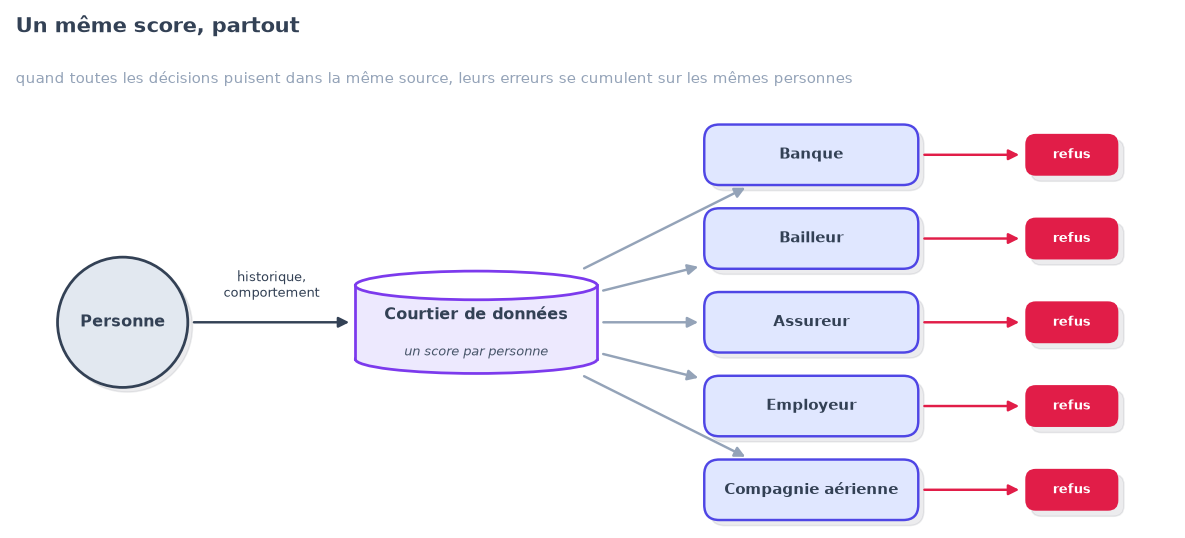

In [3]:
d = Diagram(12.5, 4.6, title="Un même score, partout",
            subtitle="quand toutes les décisions puisent dans la même source, leurs erreurs se cumulent sur les mêmes personnes")
d.box("p", 1.2, 2.2, "Personne", kind="user", w=1.4, color=SLATE)
d.box("cb", 5.0, 2.2, "Courtier de données", sub="un score par personne", color=VIOLET, kind="db", w=2.6, h=1.1)
orgs = ["Banque", "Bailleur", "Assureur", "Employeur", "Compagnie aérienne"]
for i, o in enumerate(orgs):
    y = 4.0 - i * 0.9
    d.box(f"o{i}", 8.6, y, o, color=INDIGO, w=2.3, h=0.65, fontsize=9.5)
    d.box(f"r{i}", 11.4, y, "refus", color=ROSE, kind="tag", w=1.0, h=0.45, fontsize=8.5)
    d.arrow("cb", f"o{i}", color=GRAY)
    d.arrow(f"o{i}", f"r{i}", color=ROSE)
d.arrow("p", "cb", "historique,\ncomportement", label_offset=(0, 0.4))
d.show()

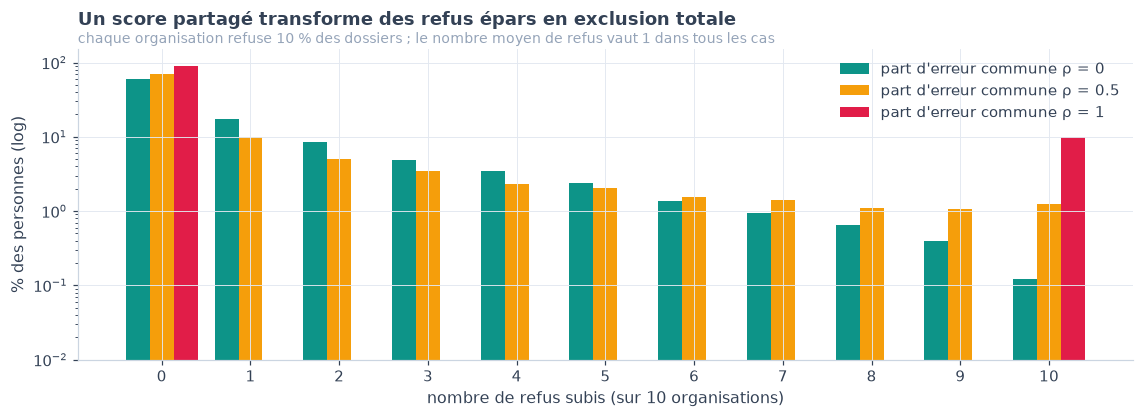

,jamais refusé (%),refusé 8 fois ou plus (%),dont risque réel sous la médiane (%)
ρ,,,
0.0,59.74,1.15,0.000
0.5,70.83,3.40,0.588
1.0,90.00,10.00,4.700


In [4]:
res = {}
for rho in (0.0, 0.5, 1.0):
    c, risk = et.exclusion_counts(n_people=10_000, n_orgs=10, reject_frac=0.1, rho=rho, seed=0)
    res[rho] = (c, risk)
fig, ax = plt.subplots(figsize=(10.5, 3.9))
w = 0.27
for j, (rho, col) in enumerate([(0.0, TEAL), (0.5, AMBER), (1.0, ROSE)]):
    c = res[rho][0]
    freq = np.bincount(c, minlength=11) / len(c) * 100
    ax.bar(np.arange(11) + (j - 1) * w, freq, width=w, color=col, label=f"part d'erreur commune ρ = {rho:g}")
ax.set_yscale("log"); ax.set_ylim(0.01, 150)
ax.set_xticks(range(11))
ax.set_xlabel("nombre de refus subis (sur 10 organisations)"); ax.set_ylabel("% des personnes (log)")
ax.set_title("Un score partagé transforme des refus épars en exclusion totale")
subtitle(ax, "chaque organisation refuse 10 % des dossiers ; le nombre moyen de refus vaut 1 dans tous les cas")
ax.legend()
plt.tight_layout(); plt.show()

rows = []
for rho, (c, risk) in res.items():
    prison = c >= 8
    rows.append({"ρ": rho, "jamais refusé (%)": (c == 0).mean() * 100,
                 "refusé 8 fois ou plus (%)": prison.mean() * 100,
                 "dont risque réel sous la médiane (%)": (risk[prison] < np.median(risk)).mean() * 100
                 if prison.any() else np.nan})
pd.DataFrame(rows).set_index("ρ")

Le nombre **moyen** de refus est le même dans les trois cas (une personne sur dix est
refusée par chaque organisation), mais sa **répartition** change tout. Avec des erreurs
indépendantes ($\rho = 0$), 60 % des gens ne sont jamais refusés et presque personne
n'est refusé partout : un refus est rattrapé ailleurs. Avec un score commun
($\rho = 1$), 10 % de la population est refusée par **les dix** organisations et 90 %
ne le sont jamais. Parmi ces exclus, environ 5 % ont pourtant un risque réel
**inférieur à la médiane** : 47 personnes sur 10 000, exclues de partout pour avoir été
mal notées une seule fois, par la seule source que tout le monde consulte. Avec des
erreurs indépendantes, aucune personne sous la médiane n'atteint 8 refus.

> **À retenir.** Une organisation prudente refuse au moindre doute, parce qu'une erreur
> lui coûte plus qu'une occasion manquée. Quand toutes les décisions puisent dans la
> même source, les erreurs ne se compensent plus : elles se concentrent sur les mêmes
> personnes, qui se retrouvent exclues de pans entiers de la société, sans preuve ni
> appel.